# Week 05 · n-Step TD and TD(λ) — n-스텝 TD와 TD(λ)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/narame7/UOS-Reinforcement-Learning/blob/main/week05_model_free_prediction/03_n_step_td_lambda.ipynb)

슬라이드 **"$n$-Step Return"**, **"Large Random Walk Example"**, **"Averaging $n$-Step Returns"**, **"From $n$-Step TD to TD($\lambda$)"**,
**"TD($\lambda$) Weighting Function"**, **"Forward-View TD($\lambda$) on Large Random Walk"**, **"Eligibility Traces"**, **"Backward-View TD($\lambda$)"**,
**"Forward and Backward View Are Equivalent (Offline)"**,
**"MC and TD(1)"**, **"Telescoping in TD($\lambda$)"**, **"Forwards and Backwards TD($\lambda$)"** 를 재현합니다.
19-상태 random walk에서 $n$-step TD(S&B Figure 7.2), off-line $\lambda$-return(Figure 12.3), eligibility trace를 쓰는 TD($\lambda$)(Figure 12.6)를
같은 에피소드로 비교하고, forward view와 backward view의 총 갱신량이 같다는 정리를 숫자로 확인합니다.

In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# 공통 플롯 스타일 (모든 주차 노트북 동일)
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
SEQ_CMAP = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#0d366b"])
DIV_CMAP = LinearSegmentedColormap.from_list("div_blue_red", ["#1c5cab", "#86b6ef", "#f0efec", "#f0a09f", "#b8302f"])
mpl.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.prop_cycle": mpl.cycler(color=PALETTE),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#0b0b0b", "text.color": "#0b0b0b",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
    "lines.linewidth": 2, "legend.frameon": False, "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold",
})
np.set_printoptions(precision=2, suppress=True)
rng = np.random.default_rng(0)

# 이번 노트북 전용
import time
np.set_printoptions(precision=3, suppress=True, linewidth=120)
INK, MUTED = "#0b0b0b", "#52514e"

## 1. $n$-Step TD on the Large Random Walk ($n$-Step Return, Large Random Walk Example)

S&B 예제 7.1: 상태 19개(1–19), 가운데(10)에서 시작, 좌우로 1/2 확률 이동. **왼쪽 끝에 도착하면 $-1$, 오른쪽 끝이면 $+1$**, 나머지 보상 0,
$\gamma = 1$, 모든 추정값은 **0으로 초기화**. 참 가치는 $v_\pi(i) = i/10 - 1$ ($-0.9, -0.8, \dots, 0.9$) 입니다.

$n$-step 리턴 $G_t^{(n)} = R_{t+1} + \gamma R_{t+2} + \cdots + \gamma^{n-1}R_{t+n} + \gamma^n V(S_{t+n})$ 을 목표로
$V(S_t) \leftarrow V(S_t) + \alpha\,(G_t^{(n)} - V(S_t))$ 를 적용합니다. 종료를 넘어가면 $G_t^{(n)}$은 그냥 전체 리턴입니다.

성능 지표(책과 동일): 각 에피소드가 끝났을 때 19개 상태의 RMS 오차를 **처음 10개 에피소드**에 대해 평균하고, 다시 **100번의 실행**에 대해 평균.
책처럼 모든 $(n, \alpha)$ 조합이 **같은 walk들**을 사용합니다.

In [2]:
N_STATES, START = 19, 10                      # non-terminal states 1..19, terminals 0 and 20
TRUE_V = np.arange(21) / 10 - 1
TRUE_V[[0, 20]] = 0.0

# check the true values with the Bellman equation (I - P) v = r
P = np.zeros((19, 19))
r = np.zeros(19)
for i in range(19):                           # row i <-> state i + 1
    for step, reward_if_exit in ((-1, -1.0), (1, 1.0)):
        j = i + step
        if 0 <= j < 19:
            P[i, j] = 0.5
        else:
            r[i] += 0.5 * reward_if_exit
assert np.allclose(np.linalg.solve(np.eye(19) - P, r), TRUE_V[1:20])


def generate_walk(rng):
    """One episode: states S_0..S_T (S_T is 0 or 20) and rewards R_1..R_T."""
    s = START
    states, rewards = [s], []
    while s not in (0, 20):
        s = s + 1 if rng.random() < 0.5 else s - 1
        states.append(s)
        rewards.append(-1.0 if s == 0 else (1.0 if s == 20 else 0.0))
    return np.array(states), np.array(rewards)


N_RUNS, N_EPISODES = 100, 10
walk_rng = np.random.default_rng(2024)
WALKS = [[generate_walk(walk_rng) for _ in range(N_EPISODES)] for _ in range(N_RUNS)]
print("average episode length:", np.mean([len(r) for run in WALKS for _, r in run]).round(1), "steps")


def rms_error(V):
    """RMS error over the 19 non-terminal states (last axis)."""
    return np.sqrt(np.mean((V[..., 1:20] - TRUE_V[1:20]) ** 2, axis=-1))

average episode length: 95.8 steps


In [3]:
def n_step_td_episode(V, states, rewards, n, alpha, gamma=1.0):
    """n-step TD for one episode (S&B p.144). V has one row per alpha; row-wise updates.

    The update of S_tau happens at time tau + n - 1 and uses the values at that time, i.e. after
    all updates of earlier taus - looping over tau in order reproduces the online algorithm exactly.
    """
    T = len(rewards)
    for tau in range(T):
        end = min(tau + n, T)
        G = sum(gamma ** (i - tau) * rewards[i] for i in range(tau, end))   # R_{tau+1} .. R_{end}
        if tau + n < T:
            G = G + gamma ** n * V[:, states[tau + n]]                       # bootstrap
        s = states[tau]
        V[:, s] += alpha * (G - V[:, s])


def evaluate(method, alphas, walks=WALKS, **kwargs):
    """Run `method(V, states, rewards, alpha=..., **kwargs)` on all walks.

    Returns (RMS averaged over the first 10 episodes and all runs, RMS after the 10th episode averaged over runs),
    both as arrays over alphas.
    """
    avg_over_episodes = np.zeros(len(alphas))
    after_last = np.zeros(len(alphas))
    with np.errstate(over="ignore", invalid="ignore"):          # large alphas can diverge (TD(lambda))
        for run in walks:
            V = np.zeros((len(alphas), 21))
            for states, rewards in run:
                method(V, states, rewards, alpha=alphas, **kwargs)
                avg_over_episodes += rms_error(V)
            after_last += rms_error(V)
    return avg_over_episodes / (len(walks) * len(walks[0])), after_last / len(walks)


ALPHAS = np.round(np.concatenate([np.arange(0, 0.1, 0.01), np.arange(0.1, 1.0001, 0.05)]), 3)
NS = [1, 2, 4, 8, 16, 32, 64, 128, 256, 512]

t0 = time.time()
nstep_avg, nstep_last = {}, {}
for n in NS:
    nstep_avg[n], nstep_last[n] = evaluate(n_step_td_episode, ALPHAS, n=n)
print(f"n-step TD: {len(NS)} values of n x {len(ALPHAS)} alphas x 100 runs in {time.time() - t0:.1f} s")

n-step TD: 10 values of n x 29 alphas x 100 runs in 4.1 s


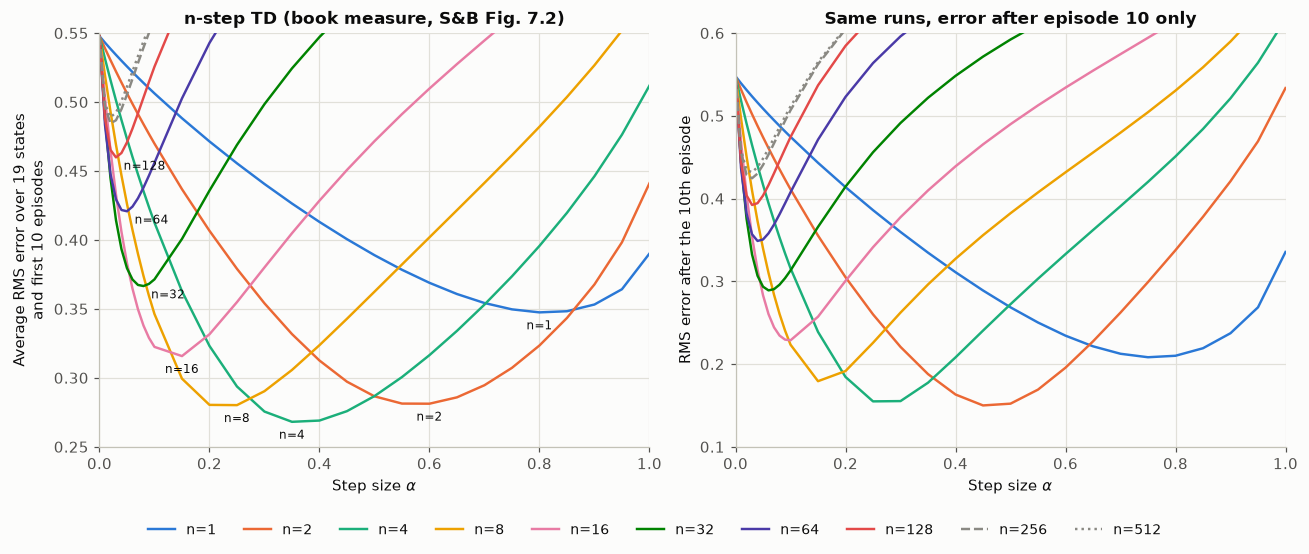

In [4]:
# line styles: the 8 categorical colors in order; n = 256 and 512 (practically MC, almost identical to n = 128)
# are folded into gray so that no generated 9th/10th hue is needed
N_STYLE = {n: dict(color=c) for n, c in zip(NS[:8], PALETTE)}
N_STYLE[256] = dict(color="#8a8983", ls="--")
N_STYLE[512] = dict(color="#8a8983", ls=":")
fmt_n = lambda n: f"n={n}"


def plot_sweep(ax, results, params, fmt, styles, ylim=(0.25, 0.55), label_min=True, no_label=(256, 512)):
    """RMS error vs alpha, one line per parameter value, with a direct label at each curve's minimum."""
    for p in params:
        y = np.where(np.isfinite(results[p]), np.minimum(results[p], 10.0), 10.0)   # diverged: off the top
        ax.plot(ALPHAS, y, lw=1.6, label=fmt(p), **styles[p])
        if label_min and p not in no_label:
            i = np.nanargmin(results[p])
            if ALPHAS[i] < 0.1:     # steep curves near alpha = 0: put the label to the right
                ax.annotate(fmt(p), (ALPHAS[i], results[p][i]), xytext=(5, -2), textcoords="offset points",
                            ha="left", va="top", fontsize=8, color=INK)
            else:
                ax.annotate(fmt(p), (ALPHAS[i], results[p][i]), xytext=(0, -5), textcoords="offset points",
                            ha="center", va="top", fontsize=8, color=INK)
    ax.set_xlim(0, 1)
    ax.set_ylim(*ylim)
    ax.set_xlabel(r"Step size $\alpha$")


def legend_below(ax, ncol):
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=ncol, fontsize=8.5, handlelength=1.8)


fig, axes = plt.subplots(1, 2, figsize=(12, 5))
plot_sweep(axes[0], nstep_avg, NS, fmt_n, N_STYLE)
axes[0].set_ylabel("Average RMS error over 19 states\nand first 10 episodes")
axes[0].set_title("n-step TD (book measure, S&B Fig. 7.2)")
plot_sweep(axes[1], nstep_last, NS, fmt_n, N_STYLE, ylim=(0.1, 0.6), label_min=False)
axes[1].set_ylabel("RMS error after the 10th episode")
axes[1].set_title("Same runs, error after episode 10 only")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=len(NS), fontsize=9, bbox_to_anchor=(0.5, -0.01))
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

### 슬라이드와 비교

- 왼쪽이 책의 지표로 그린 S&B Figure 7.2입니다. **중간 크기의 $n$(4–8)이 가장 좋고**, $n=1$(TD(0))과 $n=512$(사실상 MC)가 양 극단에서 나쁩니다.
  최솟값 약 0.27(책 ≈ 0.25–0.26), $n=1$의 최적 $\alpha \approx 0.8$ 등 책의 그림과 수치가 거의 같습니다.
- 슬라이드 "Large Random Walk Example"의 그림은 **10번째 에피소드가 끝난 뒤의 RMS 오차**(슬라이드 설명 참고)라서 전체적으로 오차가 더 낮습니다(최솟값 ≈ 0.16).
  오른쪽 그림이 같은 지표이며 슬라이드 그림과 일치합니다(오른쪽 그림: $n=1$ 최솟값 ≈ 0.2 at $\alpha \approx 0.75$, $n=2$ ≈ 0.15 at $\alpha \approx 0.45$).
  책의 지표는 에피소드 1–10의 오차를 모두 평균하므로 초반의 큰 오차가 포함되어 더 높습니다. 결론(중간 $n$이 최적)은 두 지표에서 같습니다.

In [5]:
print(f"{'n':>4s} {'best alpha':>10s} {'min avg RMS (book)':>19s} {'min RMS after ep. 10':>21s}")
for n in NS:
    i, j = nstep_avg[n].argmin(), nstep_last[n].argmin()
    print(f"{n:4d} {ALPHAS[i]:10.2f} {nstep_avg[n][i]:19.3f} {nstep_last[n][j]:14.3f} (a={ALPHAS[j]:.2f})")

assert all(np.isclose(nstep_avg[n][0], np.sqrt(0.3)) for n in NS)          # alpha = 0: V = 0 -> sqrt(0.3) = 0.548
best_n = min(NS, key=lambda n: nstep_avg[n].min())
assert best_n in (2, 4, 8)                                                  # intermediate n is best
assert nstep_avg[best_n].min() < 0.28 and nstep_avg[1].min() > 0.32 and nstep_avg[512].min() > 0.45

   n best alpha  min avg RMS (book)  min RMS after ep. 10
   1       0.80               0.347          0.208 (a=0.75)
   2       0.60               0.281          0.150 (a=0.45)
   4       0.35               0.268          0.155 (a=0.25)
   8       0.25               0.280          0.179 (a=0.15)
  16       0.15               0.316          0.229 (a=0.10)
  32       0.08               0.367          0.289 (a=0.06)
  64       0.05               0.421          0.349 (a=0.04)
 128       0.03               0.460          0.392 (a=0.03)
 256       0.02               0.485          0.424 (a=0.03)
 512       0.02               0.489          0.432 (a=0.03)


## 2. Averaging $n$-Step Returns → $\lambda$-return (Averaging $n$-Step Returns, TD($\lambda$) Weighting Function)

서로 다른 $n$의 리턴을 평균해도 좋은 목표값이 됩니다. 슬라이드의 예: $\frac{1}{3}G_t^{(1)} + \frac{2}{3}G_t^{(3)}$.
모든 $n$을 가중치 $(1-\lambda)\lambda^{n-1}$로 평균한 것이 $\lambda$-return 입니다:
$$G_t^{\lambda} = (1-\lambda)\sum_{n=1}^{T-t-1}\lambda^{n-1}G_t^{(n)} + \lambda^{T-t-1}G_t .$$
에피소드가 끝난 뒤의 $n$-step 리턴은 모두 $G_t$이므로 남은 가중치 $\lambda^{T-t-1}$은 실제 최종 리턴에 붙습니다.
이 식은 뒤에서부터 $G_t^{\lambda} = R_{t+1} + \gamma\big[(1-\lambda)V(S_{t+1}) + \lambda G_{t+1}^{\lambda}\big]$ 로 한 번에 계산할 수도 있습니다(S&B 연습문제 12.1).

In [6]:
def n_step_return(states, rewards, V, t, n, gamma=1.0):
    """G_t^(n) with a fixed value table V (1-D)."""
    T = len(rewards)
    end = min(t + n, T)
    G = sum(gamma ** (i - t) * rewards[i] for i in range(t, end))
    if t + n < T:
        G += gamma ** n * V[states[t + n]]
    return G


def lambda_return_by_weights(states, rewards, V, t, lam, gamma=1.0):
    """G_t^lambda as the weighted average of all n-step returns (S&B eq. 12.3)."""
    T = len(rewards)
    G = sum((1 - lam) * lam ** (n - 1) * n_step_return(states, rewards, V, t, n, gamma) for n in range(1, T - t))
    return G + lam ** (T - t - 1) * n_step_return(states, rewards, V, t, T - t, gamma)


def lambda_returns(states, rewards, V, lam, gamma=1.0):
    """All G_t^lambda of an episode by the backward recursion. V may have a leading (alpha) axis."""
    T = len(rewards)
    G = np.zeros(V.shape[:-1] + (T,))
    g = np.zeros(V.shape[:-1])                           # G_T^lambda = 0 (V of terminal = 0)
    for t in reversed(range(T)):
        g = rewards[t] + gamma * ((1 - lam) * V[..., states[t + 1]] + lam * g)
        G[..., t] = g
    return G


states, rewards = WALKS[0][0]
V_demo = np.random.default_rng(1).uniform(-0.5, 0.5, 21)
V_demo[[0, 20]] = 0.0
G1, G3 = n_step_return(states, rewards, V_demo, 0, 1), n_step_return(states, rewards, V_demo, 0, 3)
print(f"episode length T = {len(rewards)}, final reward {rewards[-1]:+.0f}; arbitrary V for illustration")
print(f"G^(1) = {G1:.3f},  G^(3) = {G3:.3f},  1/3 G^(1) + 2/3 G^(3) = {G1 / 3 + 2 * G3 / 3:.3f}")
for lam in (0.0, 0.5, 0.9, 1.0):
    by_w = lambda_return_by_weights(states, rewards, V_demo, 0, lam)
    by_rec = lambda_returns(states, rewards, V_demo, lam)[0]
    print(f"lambda = {lam:3.1f}:  G^lambda by weights = {by_w:+.6f},  by recursion = {by_rec:+.6f}")
    assert np.isclose(by_w, by_rec)
assert np.isclose(lambda_returns(states, rewards, V_demo, 0.0)[0], G1)                     # lambda = 0 -> TD target
assert np.isclose(lambda_returns(states, rewards, V_demo, 1.0)[0], rewards.sum())          # lambda = 1 -> MC return

episode length T = 32, final reward +1; arbitrary V for illustration
G^(1) = -0.472,  G^(3) = 0.038,  1/3 G^(1) + 2/3 G^(3) = -0.132
lambda = 0.0:  G^lambda by weights = -0.472441,  by recursion = -0.472441
lambda = 0.5:  G^lambda by weights = -0.162897,  by recursion = -0.162897
lambda = 0.9:  G^lambda by weights = +0.020611,  by recursion = +0.020611
lambda = 1.0:  G^lambda by weights = +1.000000,  by recursion = +1.000000


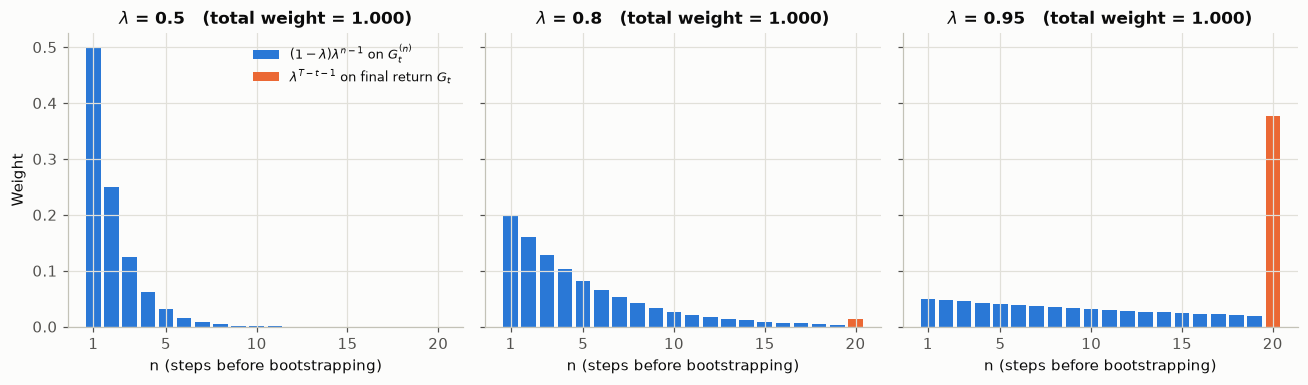

In [7]:
steps_left = 20                                # T - t
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for ax, lam in zip(axes, (0.5, 0.8, 0.95)):
    n = np.arange(1, steps_left)
    w = (1 - lam) * lam ** (n - 1)
    w_final = lam ** (steps_left - 1)
    ax.bar(n, w, color=PALETTE[0], width=0.8, label=r"$(1-\lambda)\lambda^{n-1}$ on $G_t^{(n)}$")
    ax.bar([steps_left], [w_final], color=PALETTE[1], width=0.8, label=r"$\lambda^{T-t-1}$ on final return $G_t$")
    ax.set_title(rf"$\lambda$ = {lam}   (total weight = {w.sum() + w_final:.3f})")
    ax.set_xlabel("n (steps before bootstrapping)")
    ax.set_xticks([1, 5, 10, 15, 20])
    assert np.isclose(w.sum() + w_final, 1.0)
axes[0].set_ylabel("Weight")
axes[0].legend(loc="upper right", fontsize=8.5)
plt.tight_layout()
plt.show()

슬라이드 "TD($\lambda$) Weighting Function"(S&B Figure 12.2)과 같은 모양입니다: 가중치가 $\lambda$씩 기하급수로 줄고, 남은 몫 전부가 실제 최종 리턴에 붙으며, 합은 항상 1입니다.
$\lambda$가 클수록 먼 미래(=MC 쪽)에 가중치가 많이 갑니다. $\lambda=0.95$에서는 최종 리턴의 가중치 $0.95^{19} \approx 0.38$이 가장 큰 막대입니다.

## 3. Forward-View TD($\lambda$) on the Large Random Walk (Forward-View TD($\lambda$) on Large Random Walk)

**Off-line $\lambda$-return 알고리즘**(S&B 12.1절): 에피소드 동안에는 $V$를 바꾸지 않고, 끝난 뒤 $t = 0, \dots, T-1$ 순서로
$V(S_t) \leftarrow V(S_t) + \alpha\,(G_t^{\lambda} - V(S_t))$ 를 적용합니다($G_t^\lambda$는 에피소드 동안 고정된 $V$로 계산).
1절과 같은 walk, 같은 지표로 $\lambda \in \{0, .4, .8, .9, .95, .975, .99, 1\}$을 비교합니다.

off-line lambda-return: 1.7 s


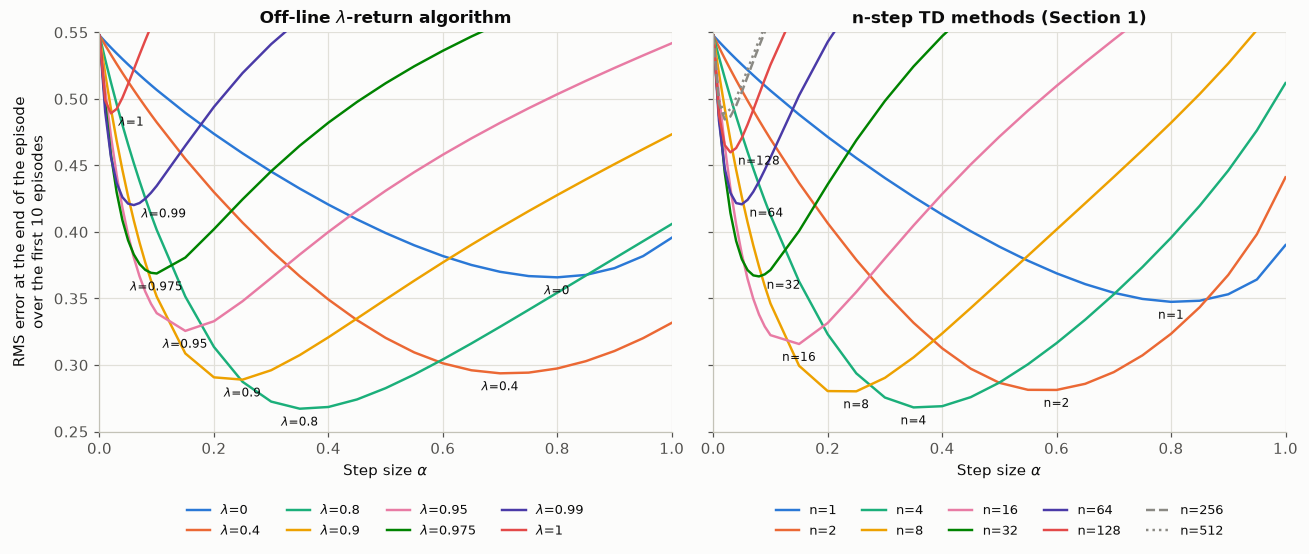

 lambda best alpha  min RMS
      0       0.80    0.366
    0.4       0.70    0.294
    0.8       0.35    0.267
    0.9       0.25    0.289
   0.95       0.15    0.326
  0.975       0.10    0.369
   0.99       0.06    0.420
      1       0.02    0.489


In [8]:
def offline_lambda_return_episode(V, states, rewards, lam, alpha, gamma=1.0):
    """Forward view: compute all lambda-returns with the episode's (fixed) V, then update in order t = 0..T-1."""
    G = lambda_returns(states, rewards, V, lam, gamma)
    for t in range(len(rewards)):
        s = states[t]
        V[:, s] += alpha * (G[:, t] - V[:, s])


LAMBDAS = [0.0, 0.4, 0.8, 0.9, 0.95, 0.975, 0.99, 1.0]
L_STYLE = {lam: dict(color=c) for lam, c in zip(LAMBDAS, PALETTE)}
fmt_l = lambda lam: rf"$\lambda$={lam:g}"
t0 = time.time()
lret_avg = {lam: evaluate(offline_lambda_return_episode, ALPHAS, lam=lam)[0] for lam in LAMBDAS}
print(f"off-line lambda-return: {time.time() - t0:.1f} s")

fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), sharey=True)
plot_sweep(axes[0], lret_avg, LAMBDAS, fmt_l, L_STYLE)
axes[0].set_title(r"Off-line $\lambda$-return algorithm")
axes[0].set_ylabel("RMS error at the end of the episode\nover the first 10 episodes")
plot_sweep(axes[1], nstep_avg, NS, fmt_n, N_STYLE)
axes[1].set_title("n-step TD methods (Section 1)")
legend_below(axes[0], 4)
legend_below(axes[1], 5)
plt.tight_layout()
plt.show()

print(f"{'lambda':>7s} {'best alpha':>10s} {'min RMS':>8s}")
for lam in LAMBDAS:
    i = lret_avg[lam].argmin()
    print(f"{lam:7g} {ALPHAS[i]:10.2f} {lret_avg[lam][i]:8.3f}")

### 슬라이드와 비교

슬라이드 그림(S&B Figure 12.3)과 같이 **중간 $\lambda$(0.8 근처)가 가장 좋고**, 최솟값(≈0.27)은 가장 좋은 $n$-step TD와 비슷합니다.
$\lambda=0$은 TD(0), $\lambda=1$은 MC와 같은 목표를 쓰므로 각각 $n=1$, $n=512$ 곡선과 닮았습니다.
큰 $\alpha$에서는 off-line $\lambda$-return이 $n$-step TD보다 조금 낫다는 책의 관찰도 보입니다(예: $\lambda=0.4$ vs. $n=2$, $\alpha=1$).

In [9]:
best_lam = min(LAMBDAS, key=lambda l: lret_avg[l].min())
print("best lambda:", best_lam, " best n:", best_n)
assert 0.4 <= best_lam <= 0.95
assert abs(lret_avg[best_lam].min() - nstep_avg[best_n].min()) < 0.03
assert np.allclose(lret_avg[0.0][:5], nstep_avg[1][:5], atol=0.01)       # lambda = 0 ~ one-step TD at small alpha

best lambda: 0.8  best n: 4


## 4. Eligibility Traces (Eligibility Traces)

$$E_0(s) = 0, \qquad E_t(s) = \gamma\lambda\,E_{t-1}(s) + \mathbf{1}(S_t = s)$$
방문할 때마다 1씩 쌓이고(빈도 heuristic) 방문하지 않으면 $\gamma\lambda$ 배로 줄어듭니다(최근성 heuristic).
왼쪽: 한 상태를 슬라이드 그림처럼 몰아서, 또 띄엄띄엄 방문할 때의 trace. 오른쪽: 실제 19-상태 walk에서 모든 상태의 trace.

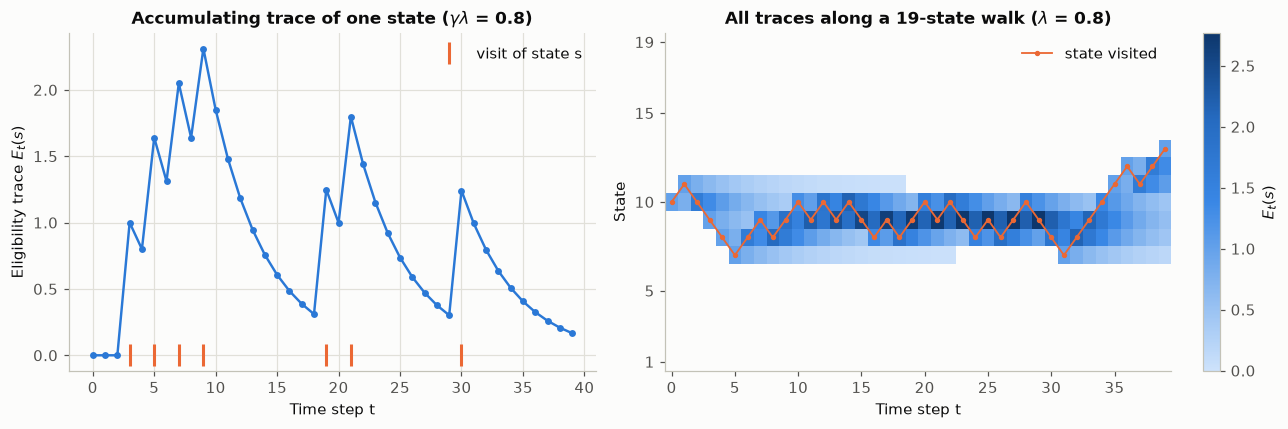

In [10]:
def eligibility_traces(states, n_states, lam, gamma=1.0):
    """Accumulating traces E_t(s) for t = 0..T-1 (rows) along the visited states S_0..S_{T-1}."""
    E = np.zeros(n_states)
    history = []
    for s in states:
        E = gamma * lam * E
        E[s] += 1.0
        history.append(E.copy())
    return np.array(history)


visit_times = [3, 5, 7, 9, 19, 21, 30]
T_demo = 40
single = eligibility_traces([0 if t in visit_times else 1 for t in range(T_demo)], 2, lam=0.8)[:, 0]

states_walk = WALKS[3][0][0][:-1]                  # S_0..S_{T-1} of one walk
traces = eligibility_traces(states_walk, 21, lam=0.8)[:40]

fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1, 1.2]})
ax = axes[0]
ax.plot(range(T_demo), single, color=PALETTE[0], marker="o", ms=3.5, lw=1.6)
ax.plot(visit_times, np.zeros(len(visit_times)), "|", color=PALETTE[1], ms=14, mew=2, label="visit of state s")
ax.set_xlabel("Time step t")
ax.set_ylabel(r"Eligibility trace $E_t(s)$")
ax.set_title(r"Accumulating trace of one state ($\gamma\lambda$ = 0.8)")
ax.legend(loc="upper right")

ax = axes[1]
im = ax.imshow(np.ma.masked_less(traces[:, 1:20].T, 0.02), origin="lower", aspect="auto", cmap=SEQ_CMAP, vmin=0,
               extent=(-0.5, len(traces) - 0.5, 0.5, 19.5))
ax.plot(range(len(traces)), states_walk[:len(traces)], color=PALETTE[1], lw=1.2, marker="o", ms=2.5, label="state visited")
ax.grid(False)
ax.set_xlabel("Time step t")
ax.set_ylabel("State")
ax.set_yticks([1, 5, 10, 15, 19])
ax.set_title(r"All traces along a 19-state walk ($\lambda$ = 0.8)")
ax.legend(loc="upper right")
fig.colorbar(im, ax=ax, label=r"$E_t(s)$")
plt.tight_layout()
plt.show()

여러 번 연달아 방문한 상태는 trace가 1보다 커지고(빈도), 마지막 방문 후 시간이 지날수록 지수적으로 사라집니다(최근성).
오른쪽 그림에서 trace는 에이전트가 지나간 자리에 남는 "꼬리"이며, TD 오차 $\delta_t$가 생기면 이 꼬리에 비례해 과거 상태들이 함께 갱신됩니다.

## 5. Backward-View TD($\lambda$) (Backward-View TD($\lambda$))

매 단계 TD 오차 $\delta_t = R_{t+1} + \gamma V(S_{t+1}) - V(S_t)$ 를 구해 **모든** 상태를 $V(s) \leftarrow V(s) + \alpha\,\delta_t\,E_t(s)$ 로 갱신합니다(온라인).
미래를 기다릴 필요가 없으므로 에피소드 도중에도 학습합니다. S&B Figure 12.6처럼 off-line $\lambda$-return과 나란히 비교합니다.

TD(lambda): 1.9 s


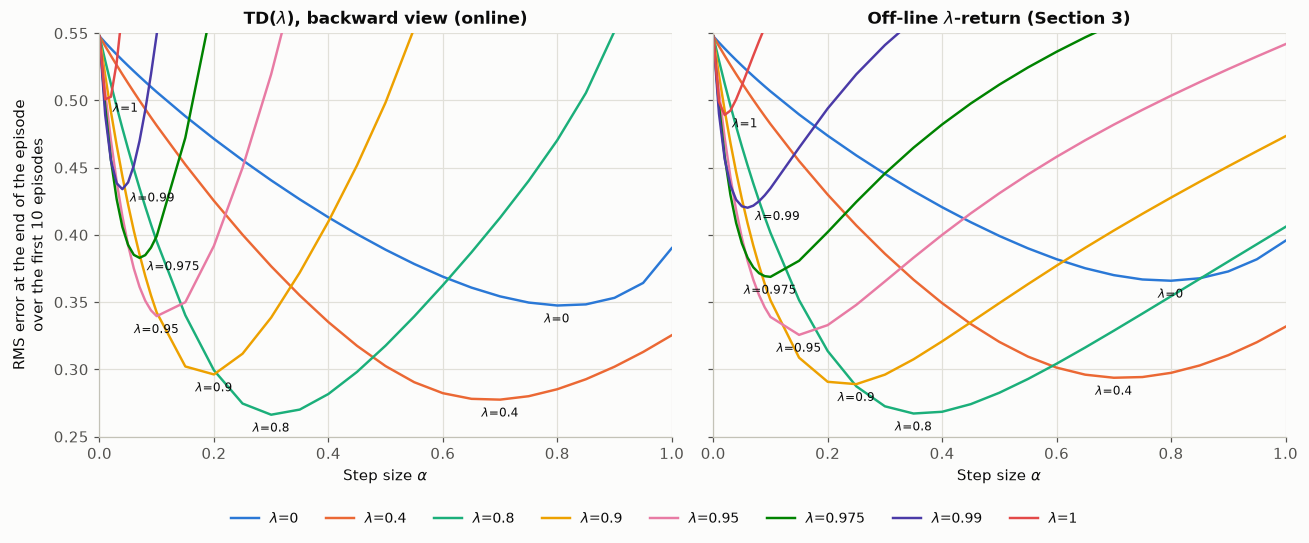

In [11]:
def td_lambda_episode(V, states, rewards, lam, alpha, gamma=1.0):
    """Backward view, online, accumulating traces. V has one row per alpha; E is shared (it does not depend on V)."""
    E = np.zeros(V.shape[-1])
    for t in range(len(rewards)):
        s, s_next = states[t], states[t + 1]
        E *= gamma * lam
        E[s] += 1.0
        delta = rewards[t] + gamma * V[:, s_next] - V[:, s]          # one TD error per alpha
        V += (alpha * delta)[:, None] * E[None, :]


t0 = time.time()
tdl_avg = {lam: evaluate(td_lambda_episode, ALPHAS, lam=lam)[0] for lam in LAMBDAS}
print(f"TD(lambda): {time.time() - t0:.1f} s")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.9), sharey=True)
plot_sweep(axes[0], tdl_avg, LAMBDAS, fmt_l, L_STYLE)
axes[0].set_title(r"TD($\lambda$), backward view (online)")
axes[0].set_ylabel("RMS error at the end of the episode\nover the first 10 episodes")
plot_sweep(axes[1], lret_avg, LAMBDAS, fmt_l, L_STYLE)
axes[1].set_title(r"Off-line $\lambda$-return (Section 3)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=len(LAMBDAS), fontsize=9, bbox_to_anchor=(0.5, -0.01))
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

In [12]:
print(f"{'lambda':>7s} {'TD(l) min':>9s} {'offline min':>11s} {'max |diff|, alpha <= best/2':>28s} "
      f"{'TD(l) @ alpha=0.6':>18s} {'offline @ alpha=0.6':>20s}")
for lam in LAMBDAS:
    small = ALPHAS <= ALPHAS[lret_avg[lam].argmin()] / 2 + 1e-9    # alphas up to half the best off-line alpha
    diff_small = np.abs(tdl_avg[lam][small] - lret_avg[lam][small]).max()
    at06_td, at06_off = tdl_avg[lam][ALPHAS == 0.6][0], lret_avg[lam][ALPHAS == 0.6][0]
    print(f"{lam:7g} {np.nanmin(tdl_avg[lam]):9.3f} {lret_avg[lam].min():11.3f} {diff_small:28.3f} "
          f"{at06_td:18.3g} {at06_off:20.3f}")
    assert diff_small < 0.015                                            # virtually identical at small alpha
    assert abs(np.nanmin(tdl_avg[lam]) - lret_avg[lam].min()) < 0.025    # similar best performance
assert not (tdl_avg[0.99][ALPHAS == 0.6] < 1)                            # large lambda + large alpha: diverges

 lambda TD(l) min offline min  max |diff|, alpha <= best/2  TD(l) @ alpha=0.6  offline @ alpha=0.6
      0     0.347       0.366                        0.008              0.369                0.382
    0.4     0.277       0.294                        0.012              0.282                0.301
    0.8     0.266       0.267                        0.011              0.363                0.304
    0.9     0.296       0.289                        0.009              0.628                0.377
   0.95     0.340       0.326                        0.006           4.79e+12                0.458
  0.975     0.383       0.369                        0.003           5.65e+57                0.536
   0.99     0.434       0.420                        0.002          1.58e+129                0.623
      1     0.501       0.489                        0.002                nan                0.749


책의 결론(S&B Figure 12.6)과 같습니다.

- $\alpha$가 작을 때(최적 $\alpha$의 절반 이하) 두 알고리즘의 오차는 0.015 이내로 **거의 같고**, 각자의 최솟값도 0.02 이내로 비슷합니다.
- $\alpha$가 크면 off-line $\lambda$-return은 조금 나빠질 뿐이지만, $\lambda \geq 0.8$의 TD($\lambda$)는 훨씬 나빠지고 $\lambda \geq 0.95$에서는 **발산**합니다(표의 $\alpha=0.6$ 열).
  누적 trace가 1보다 커질 수 있어 한 번의 갱신 크기가 $\alpha E_t(s)$가 되기 때문입니다. 그림에서 곡선이 위로 사라지는 부분이 이에 해당합니다.
- 반대로 $\lambda = 0, 0.4$에서는 온라인 TD($\lambda$)가 오히려 약간 낫습니다. 에피소드 도중에 이미 갱신된 값을 다음 목표에 쓰기 때문입니다.

## 6. Forward = Backward (Forward and Backward View Are Equivalent (Offline), MC and TD(1), Telescoping in TD($\lambda$))

슬라이드의 정리: 에피소드 동안 $V$를 고정하고 갱신을 모아 두었다가 끝에 한 번에 적용(off-line)하면,
$$\sum_{t} \alpha\,\delta_t E_t(s) \;=\; \sum_{t} \alpha\left(G_t^{\lambda} - V(S_t)\right)\mathbf{1}(S_t = s) \quad \text{for every } s.$$
핵심은 telescoping: $G_t^{\lambda} - V(S_t) = \delta_t + \gamma\lambda\,\delta_{t+1} + (\gamma\lambda)^2\delta_{t+2} + \cdots$.
임의의 $V$, 여러 $\gamma, \lambda$에서 숫자로 확인합니다.

In [13]:
def forward_total_update(V, states, rewards, lam, alpha, gamma):
    """sum_t alpha (G_t^lambda - V(S_t)) 1(S_t = s), with V fixed during the episode."""
    G = lambda_returns(states, rewards, V, lam, gamma)
    total = np.zeros_like(V)
    np.add.at(total, states[:-1], alpha * (G - V[states[:-1]]))
    return total


def backward_total_update(V, states, rewards, lam, alpha, gamma):
    """sum_t alpha delta_t E_t(s), with V fixed during the episode."""
    E = np.zeros_like(V)
    total = np.zeros_like(V)
    for t in range(len(rewards)):
        E = gamma * lam * E
        E[states[t]] += 1.0
        delta = rewards[t] + gamma * V[states[t + 1]] - V[states[t]]
        total += alpha * delta * E
    return total


states, rewards = WALKS[5][0]
V_fixed = np.random.default_rng(3).uniform(-1, 1, 21)
V_fixed[[0, 20]] = 0.0
alpha = 0.1
print(f"episode with T = {len(rewards)} steps, arbitrary V, alpha = {alpha}")
for gamma in (1.0, 0.9):
    for lam in (0.0, 0.5, 0.9, 1.0):
        fwd = forward_total_update(V_fixed, states, rewards, lam, alpha, gamma)
        bwd = backward_total_update(V_fixed, states, rewards, lam, alpha, gamma)
        print(f"gamma = {gamma:3.1f}, lambda = {lam:3.1f}:  max_s |forward - backward| = {np.abs(fwd - bwd).max():.1e}")
        assert np.allclose(fwd, bwd)

# telescoping of TD errors, time step by time step
gamma, lam = 0.9, 0.7
deltas = rewards + gamma * V_fixed[states[1:]] - V_fixed[states[:-1]]
G_lam = lambda_returns(states, rewards, V_fixed, lam, gamma)
T = len(rewards)
telescoped = np.array([sum((gamma * lam) ** (k - t) * deltas[k] for k in range(t, T)) for t in range(T)])
assert np.allclose(telescoped, G_lam - V_fixed[states[:-1]])
print(f"telescoping G_t^lambda - V(S_t) = sum_k (gamma lambda)^(k-t) delta_k holds for all {T} time steps")

episode with T = 64 steps, arbitrary V, alpha = 0.1
gamma = 1.0, lambda = 0.0:  max_s |forward - backward| = 0.0e+00
gamma = 1.0, lambda = 0.5:  max_s |forward - backward| = 1.1e-16
gamma = 1.0, lambda = 0.9:  max_s |forward - backward| = 1.1e-16
gamma = 1.0, lambda = 1.0:  max_s |forward - backward| = 2.2e-16
gamma = 0.9, lambda = 0.0:  max_s |forward - backward| = 0.0e+00
gamma = 0.9, lambda = 0.5:  max_s |forward - backward| = 1.1e-16
gamma = 0.9, lambda = 0.9:  max_s |forward - backward| = 2.2e-16
gamma = 0.9, lambda = 1.0:  max_s |forward - backward| = 2.8e-16
telescoping G_t^lambda - V(S_t) = sum_k (gamma lambda)^(k-t) delta_k holds for all 64 time steps


### TD(1)과 MC

$\lambda = 1$이면 $G_t^{\lambda} = G_t$ 이므로 off-line TD(1)의 총 갱신은 **every-visit MC**의 총 갱신 $\sum_t \alpha(G_t - V(S_t))\mathbf{1}(S_t=s)$ 과 정확히 같습니다(슬라이드 "MC and TD(1)", "Telescoping in TD(1)").
반면 매 단계 $V$를 바로 바꾸는 **온라인** TD($\lambda$)는 에피소드 도중 바뀐 $V$로 $\delta_t$를 계산하므로 결과가 달라지며, 그 차이는 $\alpha$가 작을수록 ($\alpha^2$ 정도로) 줄어듭니다.

In [14]:
def returns_of(rewards, gamma):
    G, g = np.zeros(len(rewards)), 0.0
    for t in reversed(range(len(rewards))):
        g = rewards[t] + gamma * g
        G[t] = g
    return G


for gamma in (1.0, 0.9):
    mc_total = np.zeros(21)
    np.add.at(mc_total, states[:-1], alpha * (returns_of(rewards, gamma) - V_fixed[states[:-1]]))
    td1_total = backward_total_update(V_fixed, states, rewards, 1.0, alpha, gamma)
    print(f"gamma = {gamma}: max_s |TD(1) offline total - every-visit MC total| = {np.abs(td1_total - mc_total).max():.1e}")
    assert np.allclose(td1_total, mc_total)

# online vs off-line after one episode (V changes during the episode in the online version)
for a in (0.1, 0.01):
    for lam in (0.0, 0.8, 1.0):
        V_on = V_fixed[None, :].copy()
        td_lambda_episode(V_on, states, rewards, lam, np.array([a]))
        V_off = V_fixed + backward_total_update(V_fixed, states, rewards, lam, a, 1.0)
        print(f"alpha = {a:4}, lambda = {lam}: max_s |V after online TD(lambda) - V after off-line update| = "
              f"{np.abs(V_on[0] - V_off).max():.4f}")

gamma = 1.0: max_s |TD(1) offline total - every-visit MC total| = 2.2e-16
gamma = 0.9: max_s |TD(1) offline total - every-visit MC total| = 2.8e-16
alpha =  0.1, lambda = 0.0: max_s |V after online TD(lambda) - V after off-line update| = 0.3041
alpha =  0.1, lambda = 0.8: max_s |V after online TD(lambda) - V after off-line update| = 0.1565
alpha =  0.1, lambda = 1.0: max_s |V after online TD(lambda) - V after off-line update| = 0.1931
alpha = 0.01, lambda = 0.0: max_s |V after online TD(lambda) - V after off-line update| = 0.0042
alpha = 0.01, lambda = 0.8: max_s |V after online TD(lambda) - V after off-line update| = 0.0018
alpha = 0.01, lambda = 1.0: max_s |V after online TD(lambda) - V after off-line update| = 0.0026


Off-line에서는 forward view(이론: $\lambda$-return)와 backward view(구현: eligibility trace)의 총 갱신이 부동소수점 오차 수준($10^{-16}$)까지 같습니다.
온라인 갱신에서는 차이가 생기지만, 5절에서 보았듯 $\alpha$가 작으면 성능은 거의 같습니다.
(정확히 일치시키는 true online TD($\lambda$)는 S&B 12.5절을 참고하세요.)

## 직접 해보기

1. 1절에서 walk 수를 5-상태 random walk로 줄이면(`N_STATES`, 보상 설정 변경) 가장 좋은 $n$이 어떻게 변하나요? (S&B 연습문제 7.3)
2. `td_lambda_episode`의 누적 trace `E[s] += 1`을 replacing trace `E[s] = 1`로 바꿔 5절 그림을 다시 그려 보세요. 큰 $\alpha$에서의 발산이 줄어드나요?
3. 3절에서 $G_t^\lambda$를 에피소드 시작 시점의 $V$가 아니라 갱신 중인 $V$로 계산하도록 바꾸면 결과가 얼마나 달라지나요?
4. 6절에서 `gamma`, `lam`, `V_fixed`를 바꿔도 forward = backward가 항상 성립하는지, 반면 온라인 차이는 $\alpha$에 따라 어떻게 커지는지 확인해 보세요.